In [2]:
R.version.string

[1] "R version 4.6.1 (2026-06-24)"

In [4]:
install.packages("palmerpenguins")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [5]:
library(palmerpenguins)

data(penguins)

head(penguins)


Attaching package: ‘palmerpenguins’


The following objects are masked from ‘package:datasets’:

    penguins, penguins_raw




species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
<fct>,<fct>,<dbl>,<dbl>,<int>,<int>,<fct>,<int>
Adelie,Torgersen,39.1,18.7,181,3750,male,2007
Adelie,Torgersen,39.5,17.4,186,3800,female,2007
Adelie,Torgersen,40.3,18.0,195,3250,female,2007
Adelie,Torgersen,NA,NA,NA,NA,NA,2007
Adelie,Torgersen,36.7,19.3,193,3450,female,2007
Adelie,Torgersen,39.3,20.6,190,3650,male,2007


In [6]:
colSums(is.na(penguins))

species            island    bill_length_mm     bill_depth_mm 
                0                 0                 2                 2 
flipper_length_mm       body_mass_g               sex              year 
                2                 2                11                 0

In [7]:
body_mass <- penguins$body_mass_g

body_mass <- na.omit(body_mass)

length(body_mass)

[1] 342

In [8]:
mean(body_mass)
median(body_mass)

[1] 4201.754

[1] 4050

In [9]:
min(body_mass)
max(body_mass)
var(body_mass)

[1] 2700

[1] 6300

[1] 643131.1

In [10]:
sd(body_mass)
quantile(body_mass, 0.25)
quantile(body_mass, 0.75)

[1] 801.9545

25% 
3550

75% 
4750

In [11]:
IQR(body_mass)

[1] 1200

In [12]:
install.packages("moments")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [13]:
library(moments)
skewness(body_mass)
kurtosis(body_mass)

[1] 0.468264

[1] 2.273757

In [14]:
aggregate(body_mass_g ~ species,
          data = penguins,
          FUN = function(x) mean(x, na.rm = TRUE))

species,body_mass_g
<fct>,<dbl>
Adelie,3700.662
Chinstrap,3733.088
Gentoo,5076.016


In [15]:
by(penguins$body_mass_g,
   penguins$species,
   summary)

penguins$species: Adelie
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.     NAs 
   2850    3350    3700    3701    4000    4775       1 
------------------------------------------------------------ 
penguins$species: Chinstrap
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   2700    3488    3700    3733    3950    4800 
------------------------------------------------------------ 
penguins$species: Gentoo
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.     NAs 
   3950    4700    5000    5076    5500    6300       1 

In [16]:
by(penguins$body_mass_g,
   penguins$species,
   function(x) {
     c(
       Variance = var(x, na.rm = TRUE),
       SD = sd(x, na.rm = TRUE)
     )
   })

penguins$species: Adelie
   Variance          SD 
210282.8918    458.5661 
------------------------------------------------------------ 
penguins$species: Chinstrap
   Variance          SD 
147713.4548    384.3351 
------------------------------------------------------------ 
penguins$species: Gentoo
   Variance          SD 
254133.1801    504.1162 

In [17]:
by(penguins$body_mass_g,
   penguins$species,
   IQR,
   na.rm = TRUE)

penguins$species: Adelie
[1] 650
------------------------------------------------------------ 
penguins$species: Chinstrap
[1] 462.5
------------------------------------------------------------ 
penguins$species: Gentoo
[1] 800

In [18]:
by(penguins$body_mass_g,
   penguins$species,
   function(x) {
     c(
       Skewness = skewness(x, na.rm = TRUE),
       Kurtosis = kurtosis(x, na.rm = TRUE)
     )
   })

penguins$species: Adelie
 Skewness  Kurtosis 
0.2824938 2.4056114 
------------------------------------------------------------ 
penguins$species: Chinstrap
 Skewness  Kurtosis 
0.2419413 3.4636806 
------------------------------------------------------------ 
penguins$species: Gentoo
  Skewness   Kurtosis 
0.06878276 2.25787092 

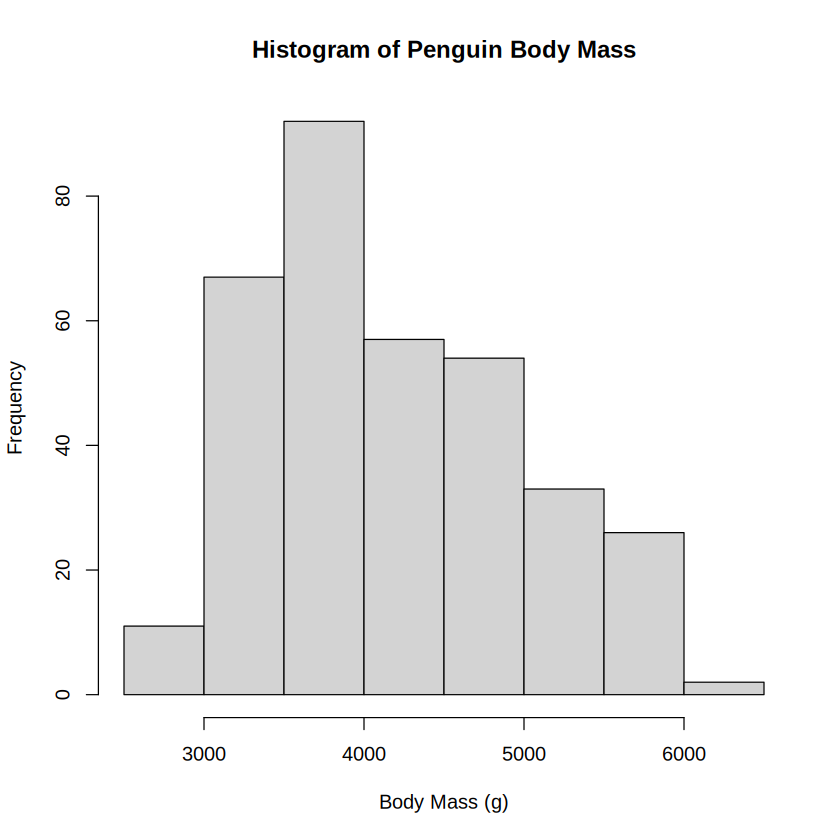

In [19]:
hist(body_mass,
     main = "Histogram of Penguin Body Mass",
     xlab = "Body Mass (g)",
     ylab = "Frequency")

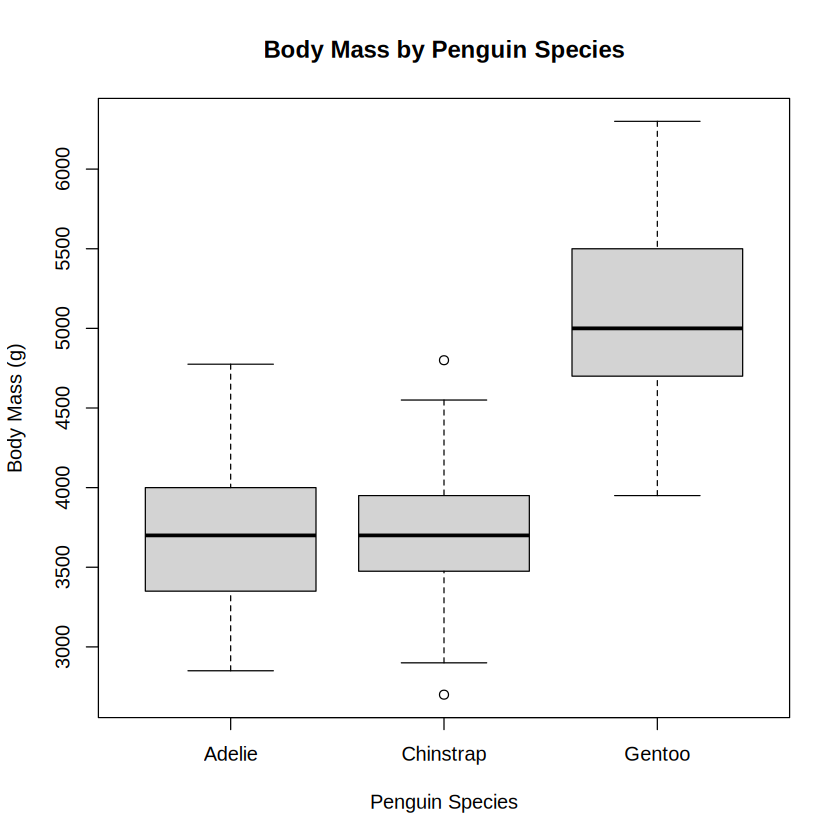

In [20]:
boxplot(body_mass_g ~ species,
        data = penguins,
        main = "Body Mass by Penguin Species",
        xlab = "Penguin Species",
        ylab = "Body Mass (g)")

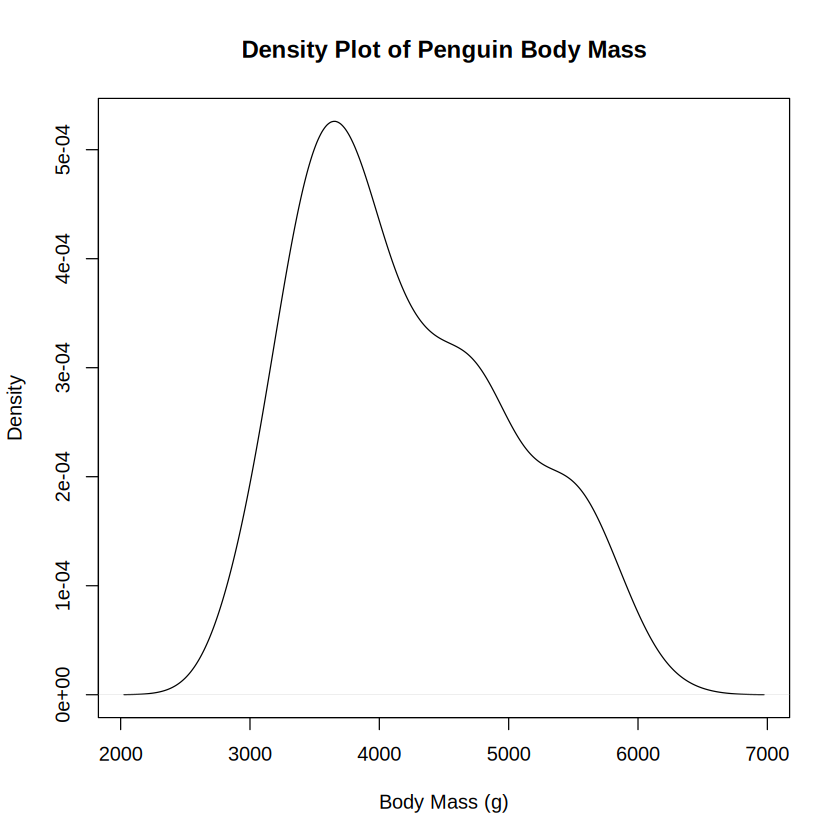

In [21]:
plot(density(body_mass),
     main = "Density Plot of Penguin Body Mass",
     xlab = "Body Mass (g)",
     ylab = "Density")

In [22]:
male_mass <- penguins$body_mass_g[penguins$sex == "male"]
female_mass <- penguins$body_mass_g[penguins$sex == "female"]

male_mass <- na.omit(male_mass)
female_mass <- na.omit(female_mass)

length(male_mass)
length(female_mass)

[1] 168

[1] 165

In [23]:
shapiro.test(male_mass)
shapiro.test(female_mass)


	Shapiro-Wilk normality test

data:  male_mass
W = 0.92504, p-value = 1.227e-07



	Shapiro-Wilk normality test

data:  female_mass
W = 0.91931, p-value = 6.155e-08


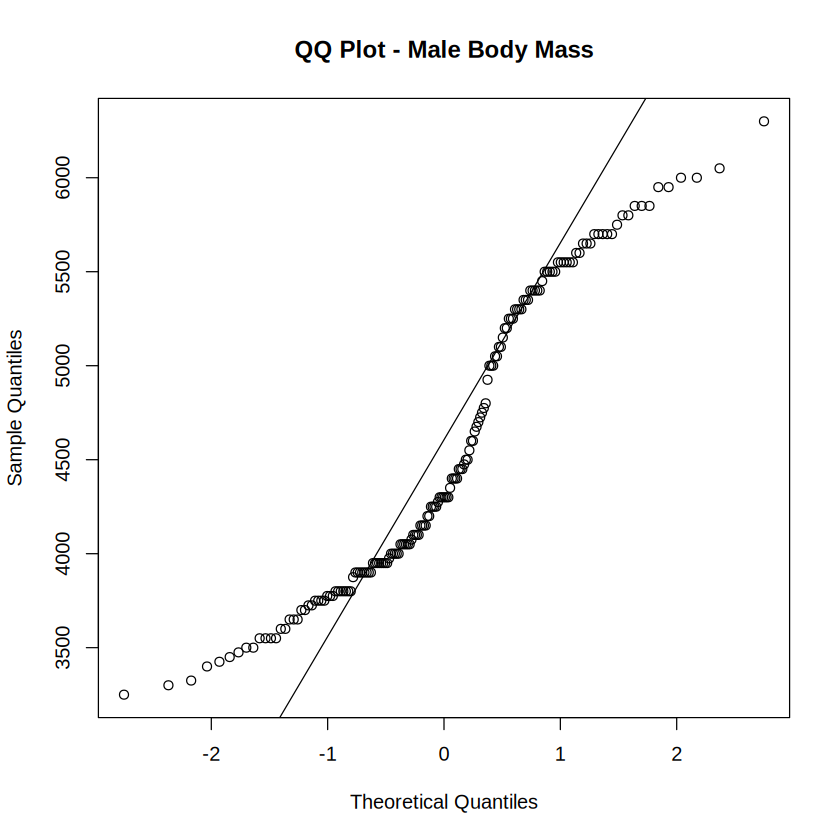

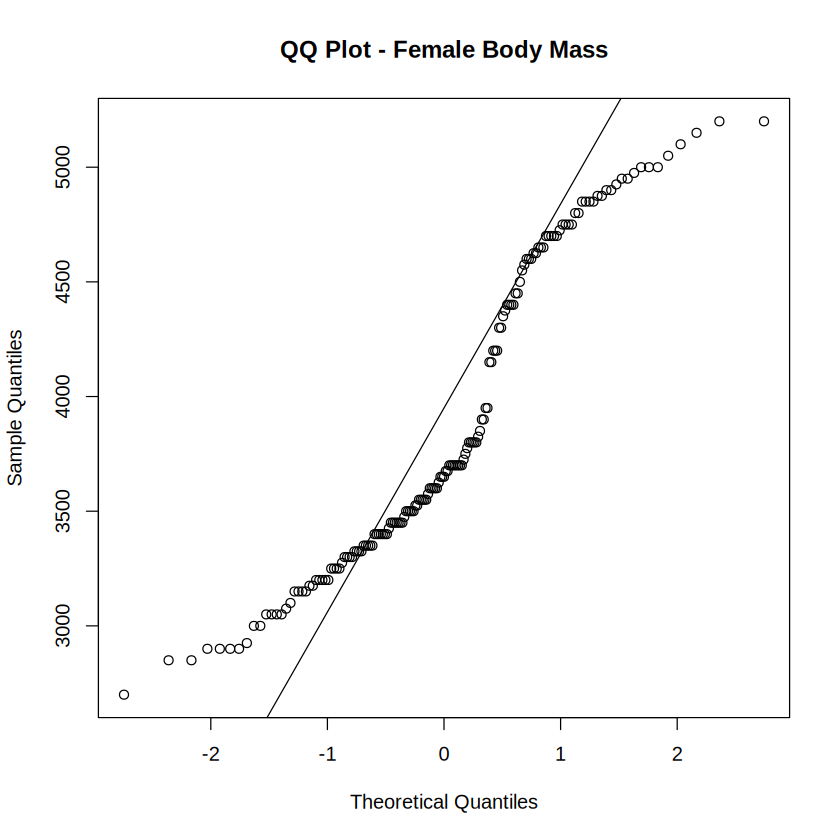

In [24]:
qqnorm(male_mass,
       main = "QQ Plot - Male Body Mass")
qqline(male_mass)
qqnorm(female_mass,
       main = "QQ Plot - Female Body Mass")
qqline(female_mass)

In [25]:
t_test_result <- t.test(male_mass,
                        female_mass,
                        var.equal = FALSE,
                        conf.level = 0.95)

t_test_result


	Welch Two Sample t-test

data:  male_mass and female_mass
t = 8.5545, df = 323.9, p-value = 4.794e-16
alternative hypothesis: true difference in means is not equal to 0
95 percent confidence interval:
 526.2453 840.5783
sample estimates:
mean of x mean of y 
 4545.685  3862.273 
